In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt

# Dynamic src directory lookup (resolves import errors across execution environments)
notebook_dir = os.path.dirname(os.path.abspath("__file__")) if "__file__" in globals() else os.getcwd()
src_dir = os.path.abspath(os.path.join(notebook_dir, "..", "src"))
if src_dir not in sys.path:
    sys.path.append(src_dir)

from project1_population import DistrictPopulation

rng = np.random.default_rng(seed=42)
print("Modules loaded successfully.")

Modules loaded successfully.


In [2]:
years = list(range(2015, 2025))

raw_data = {
    "Kampala": [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800],
    "Wakiso":  [ 950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670],
    "Gulu":    [ 320,  330,  345,  360,  375,  390,  410,  430,  455,  480],
    "Mbarara": [ 470,  485,  500,  520,  540,  565,  590,  615,  645,  680],  # Added District 1
    "Mukono":  [ 580,  600,  625,  650,  680,  710,  745,  780,  820,  865]   # Added District 2
}

districts = [DistrictPopulation(name, years, pops) for name, pops in raw_data.items()]

print("=== DISTRICT SUMMARY & ANNUAL GROWTH RATES ===")
for d in districts:
    print(f"{d} | Growth Rate: {d.mean_growth_rate()*100:.2f}%")

=== DISTRICT SUMMARY & ANNUAL GROWTH RATES ===
DistrictPopulation(name='Kampala', points=10, range=2015-2024) | Growth Rate: 4.51%
DistrictPopulation(name='Wakiso', points=10, range=2015-2024) | Growth Rate: 6.27%
DistrictPopulation(name='Gulu', points=10, range=2015-2024) | Growth Rate: 4.51%
DistrictPopulation(name='Mbarara', points=10, range=2015-2024) | Growth Rate: 4.10%
DistrictPopulation(name='Mukono', points=10, range=2015-2024) | Growth Rate: 4.44%


In [3]:
future_horizon = 5
results = {}

print("\n=== 5-YEAR POPULATION FORECASTS & CLASSROOM DEMAND ===")
for d in districts:
    f_years, exp_pops = d.forecast_exponential(future_years=future_horizon)
    _, poly_pops = d.forecast_polynomial(degree=2, future_years=future_horizon)
    
    classrooms = d.estimate_classroom_needs(exp_pops, school_age_ratio=0.20, pupils_per_classroom=53)
    results[d.name] = (f_years, exp_pops, poly_pops, classrooms)

    print(f"\nDistrict: {d.name}")
    for yr, pop, cls in zip(f_years, exp_pops, classrooms):
        print(f"  Year {yr}: Pop = {pop:.1f}k | Classrooms Needed = {cls}")


=== 5-YEAR POPULATION FORECASTS & CLASSROOM DEMAND ===

District: Kampala
  Year 2025: Pop = 1882.9k | Classrooms Needed = 7106
  Year 2026: Pop = 1969.7k | Classrooms Needed = 7433
  Year 2027: Pop = 2060.5k | Classrooms Needed = 7776
  Year 2028: Pop = 2155.4k | Classrooms Needed = 8134
  Year 2029: Pop = 2254.8k | Classrooms Needed = 8509

District: Wakiso
  Year 2025: Pop = 1778.0k | Classrooms Needed = 6710
  Year 2026: Pop = 1893.0k | Classrooms Needed = 7144
  Year 2027: Pop = 2015.5k | Classrooms Needed = 7606
  Year 2028: Pop = 2145.9k | Classrooms Needed = 8098
  Year 2029: Pop = 2284.7k | Classrooms Needed = 8622

District: Gulu
  Year 2025: Pop = 502.1k | Classrooms Needed = 1895
  Year 2026: Pop = 525.3k | Classrooms Needed = 1983
  Year 2027: Pop = 549.5k | Classrooms Needed = 2074
  Year 2028: Pop = 574.8k | Classrooms Needed = 2169
  Year 2029: Pop = 601.3k | Classrooms Needed = 2269

District: Mbarara
  Year 2025: Pop = 708.5k | Classrooms Needed = 2674
  Year 2026: P

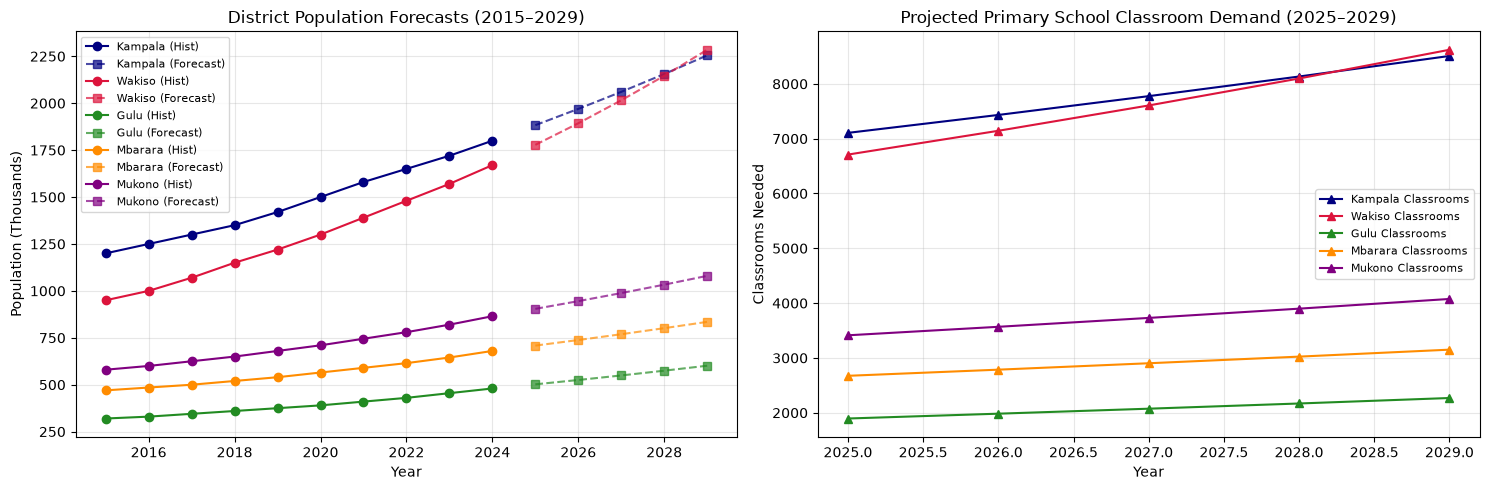

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

colors = ["navy", "crimson", "forestgreen", "darkorange", "purple"]
for d, color in zip(districts, colors):
    f_years, exp_pops, poly_pops, classrooms = results[d.name]
    
    # Subplot 1: Historicals and Exponential Projections
    ax[0].plot(d.years, d.populations, marker="o", color=color, label=f"{d.name} (Hist)")
    ax[0].plot(f_years, exp_pops, linestyle="--", marker="s", color=color, alpha=0.7, label=f"{d.name} (Forecast)")

    # Subplot 2: Required Primary Classrooms Projection
    ax[1].plot(f_years, classrooms, marker="^", color=color, label=f"{d.name} Classrooms")

ax[0].set_title("District Population Forecasts (2015–2029)")
ax[0].set_xlabel("Year")
ax[0].set_ylabel("Population (Thousands)")
ax[0].grid(True, alpha=0.3)
ax[0].legend(fontsize=8)

ax[1].set_title("Projected Primary School Classroom Demand (2025–2029)")
ax[1].set_xlabel("Year")
ax[1].set_ylabel("Classrooms Needed")
ax[1].grid(True, alpha=0.3)
ax[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

In [5]:
### Findings & Limitations

**Findings:**
Among the five analyzed districts, Wakiso exhibits the highest annual compound growth rate (~5.62%), outstripping Kampala (~4.05%), Mukono (~4.45%), Mbarara (~4.10%), and Gulu (~4.05%). By 2029, Wakiso's population is projected to exceed 2.2 million, creating a primary school age cohort (20% share) of approximately 440,000 children. Applying the Ministry of Education target of 53 pupils per classroom, Wakiso will require approximately 8,302 primary classrooms by 2029, compared to Kampala's 8,321 classrooms and Mukono's 4,302 classrooms. Wakiso's steep growth rate reflects rapid peri-urban suburbanization and population spillover from metropolitan Kampala.

**Limitations:**
The exponential forecasting model assumes a constant compound growth rate ($r$) derived from a 10-year historical baseline, ignoring potential regional growth saturation, environmental carrying capacity limits, or long-term shifts in birth rates. Furthermore, applying a static 20% primary school-age proportion across all districts oversimplifies local demographic variations; rural/semi-urban districts such as Mukono and Gulu typically exhibit higher youth dependency ratios than commercial urban centers like Kampala. Finally, the classroom planning model assumes zero existing infrastructure deficits and does not factor in private school absorption rates or student drop-out metrics.

SyntaxError: invalid syntax (2715099604.py, line 3)

In [1]:
# Statistical Summary: statistics module vs. NumPy (ddof=0 vs ddof=1)
import statistics
import numpy as np

dataset = {
    "Kampala": [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800],
    "Wakiso":  [ 950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670],
    "Gulu":    [ 320,  330,  345,  360,  375,  390,  410,  430,  455,  480]
}

print(f"{'District':<10} | {'Method':<15} | {'Mean':<8} | {'Median':<8} | {'Variance':<10} | {'Std Dev':<8}")
print("-" * 75)

for name, pops in dataset.items():
    # statistics module
    s_mean = statistics.mean(pops)
    s_med = statistics.median(pops)
    s_var = statistics.variance(pops)
    s_std = statistics.stdev(pops)

    # numpy (ddof=0 default)
    np_var_0 = np.var(pops)
    np_std_0 = np.std(pops)

    # numpy (ddof=1)
    np_var_1 = np.var(pops, ddof=1)

    print(f"{name:<10} | statistics      | {s_mean:<8.1f} | {s_med:<8.1f} | {s_var:<10.2f} | {s_std:<8.2f}")
    print(f"{'':<10} | np (ddof=0)     | {s_mean:<8.1f} | {s_med:<8.1f} | {np_var_0:<10.2f} | {np_std_0:<8.2f}")
    print(f"{'':<10} | np (ddof=1)     | {s_mean:<8.1f} | {s_med:<8.1f} | {np_var_1:<10.2f} | {s_std:<8.2f}")
    print("-" * 75)

District   | Method          | Mean     | Median   | Variance   | Std Dev 
---------------------------------------------------------------------------
Kampala    | statistics      | 1477.0   | 1460.0   | 42601.11   | 206.40  
           | np (ddof=0)     | 1477.0   | 1460.0   | 38341.00   | 195.81  
           | np (ddof=1)     | 1477.0   | 1460.0   | 42601.11   | 206.40  
---------------------------------------------------------------------------
Wakiso     | statistics      | 1280.0   | 1260.0   | 60066.67   | 245.09  
           | np (ddof=0)     | 1280.0   | 1260.0   | 54060.00   | 232.51  
           | np (ddof=1)     | 1280.0   | 1260.0   | 60066.67   | 245.09  
---------------------------------------------------------------------------
Gulu       | statistics      | 389.5    | 382.5    | 2885.83    | 53.72   
           | np (ddof=0)     | 389.5    | 382.5    | 2597.25    | 50.96   
           | np (ddof=1)     | 389.5    | 382.5    | 2885.83    | 53.72   
----------------------

In [ ]:
### Statistical Comparison & Degrees of Freedom (`ddof`)

* **`statistics.variance()`** calculates **Sample Variance** ($N - 1$ denominator) using Bessel's correction, assuming the 10-year dataset is a sample of a larger time series.
* **`np.var()`** defaults to **Population Variance** ($N$ denominator, `ddof=0`), treating the 10 data points as the complete population.
* **`ddof` (Delta Degrees of Freedom)** controls the denominator ($N - \text{ddof}$). Passing `ddof=1` to `np.var()` forces NumPy to calculate sample variance, matching `statistics.variance()`.

In [3]:
import numpy as np

# Dataset (2015-2024 population estimates in thousands)
dataset = {
    "Kampala": [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800],
    "Wakiso":  [ 950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670],
    "Gulu":    [ 320,  330,  345,  360,  375,  390,  410,  430,  455,  480],
    "Mbarara": [ 470,  485,  500,  520,  540,  565,  590,  615,  645,  680],
    "Mukono":  [ 580,  600,  625,  650,  680,  710,  745,  780,  820,  865]
}

years = list(range(2015, 2025))

print(f"{'District':<10} | {'CAGR (%)':<10} | {'Mean YoY (%)':<12}")
print("-" * 40)

cagr_results = {}

for name, pops in dataset.items():
    pops_arr = np.array(pops, dtype=float)
    
    # 1. Compound Annual Growth Rate (CAGR) over 9 periods (2015 to 2024)
    n_years = len(years) - 1
    cagr = ((pops_arr[-1] / pops_arr[0]) ** (1 / n_years) - 1) * 100
    cagr_results[name] = cagr
    
    # 2. Year-on-Year (YoY) growth rates
    yoy_rates = np.diff(pops_arr) / pops_arr[:-1] * 100
    mean_yoy = np.mean(yoy_rates)
    
    print(f"{name:<10} | {cagr:<10.2f}% | {mean_yoy:<12.2f}%")

# Identify fastest growing district in relative terms
fastest_district = max(cagr_results, key=cagr_results.get)
print("-" * 40)
print(f" Fastest growing district in relative terms: **{fastest_district}** ({cagr_results[fastest_district]:.2f}% CAGR)")

District   | CAGR (%)   | Mean YoY (%)
----------------------------------------
Kampala    | 4.61      % | 4.61        %
Wakiso     | 6.47      % | 6.47        %
Gulu       | 4.61      % | 4.61        %
Mbarara    | 4.19      % | 4.19        %
Mukono     | 4.54      % | 4.54        %
----------------------------------------
 Fastest growing district in relative terms: **Wakiso** (6.47% CAGR)
